# Machine Learning LAB 1: MODEL SELECTION

Course 2026/27: *F. Chiariotti*

The notebook contains a simple learning task over which we will implement **MODEL SELECTION AND VALIDATION**.

Complete all the **required code sections**.

### IMPORTANT for the exam:

The functions you might be required to implement in the exam will have the same signature and parameters as the ones in the labs

## Polynomial Classification on Signal to Noise Ratios

In this notebook we are going to explore the use of polynomial classification with polynomial regression. We are going to use the Numpy **polyfit** function, which performs polynomial regression.

Our use case is a communication problem: we have a set of measurements of the Signal to Noise Ratio (SNR), i.e., the quality of the communication link, in various positions. The SNR depends on two components: firstly, the noise level (which is a random variable that does not depend on position) and the signal attenuation (usually modeled as a polynomial function of the distance).

Our transmitter is in (0,0), and coordinates are in meters. In urban scenarios, the attenuation usually follows a third-degree polynomial, but it might be a fourth- or fifth-degree polynomial in more complex cases. How do we choose between different degrees? We will try with a maximum of **6**

---

## Import all the necessary Python libraries

In [27]:
import numpy as np
import scipy as sp
import pandas as pd
import itertools
from matplotlib import pyplot as plt
import random

---

## Load the data

In this case, x and y are the two coordinates, and the SNR is the thing we are trying to predict

**DO NOT CHANGE THE PRE-WRITTEN CODE UNLESS OTHERWISE SPECIFIED**

In [11]:
df = pd.read_csv('data/snr_measurements.csv',sep=';')
x = df['x'].to_numpy() # if to_numpy is not available use np.asarray(list(df['x']))
y = df['y'].to_numpy()
SNR = df['SNR'].to_numpy()
#print(x, y, SNR)

## Helper functions

These functions will help us evaluate the results

In [28]:
def compute_distance(x, y):
    # TODO: Compute the Euclidean distance from the origin
    distance = np.sqrt(x**2+y**2)
    return distance


def fit(distance, SNR, degree):  #choosing the hypothesis
    return np.polyfit(distance, SNR, deg=degree)
    

def predict(distance, poly_coeffs):   # compute h(X) in this case is the polynomial fitting of the data
    # Predict the SNR from a given model
    deg = len(poly_coeffs)
    pred = poly_coeffs[-1] # the constant parameter is the last
    for i in range(1, deg):
        pred += poly_coeff[deg-i-1] * (distance **i)
    return pred

def evaluate(distance, SNR, poly_coeffs):
    # TODO: Compute the error of the polynomial fit on the chosen data
    mse = 0 # we start at zero error
    for i in range(len(distance)):
        mse = mse + (predict(distance[i], poly_coeffs - SNR[i]))**2
    mse = mse / len(distance)
    
    return mse

def separate_test(distance, SNR, test_points):
    # TODO: Return a training set and a test set (the test_points parameter controls the number of test points).
    # The points should be selected randomly
    idx = list(range(len(distance)))
    test_idx = random.sample(idx,test_points)
    train_idx = [i for i in idx if i not in test_idx]
    x_train = distance[train_idx]
    x_test = distance[test_idx]
    y_train = SNR[train_idx]
    y_test = SNR[test_idx]
    
    return x_train, y_train, x_test, y_test

200 40


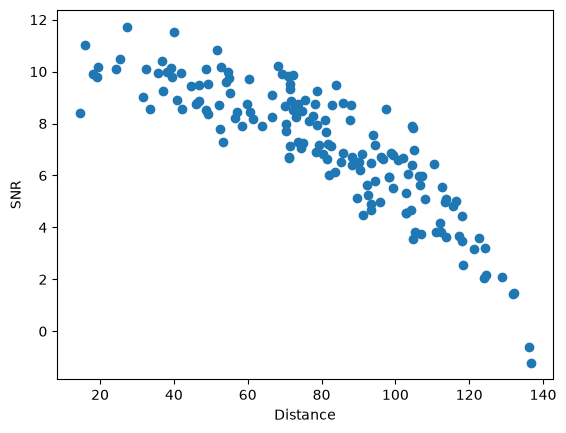

In [29]:
# TODO: separate the training and test sets and create a scatter plot of the SNR as a function of the distance

points = SNR.shape[0]
test_points = int(points * 0.2)
print(points, test_points)
distance = np.zeros(points)
for i in range(points):
    distance[i] = compute_distance(x[i] , y[i])
(x_train , y_train, x_test, y_test) = separate_test(distance,SNR, test_points)

plt.scatter(x_train, y_train)
plt.xlabel('Distance')
plt.ylabel('SNR')
plt.show()

## A. K-fold cross-validation

In this case, x and y are the two coordinates, and the SNR is the thing we are trying to predict

In [ ]:
# Function to perform the K-fold cross validation THEORY CLASS CHAPTER 5

def k_fold_cross_validation(x_train: np.ndarray, y_train: np.ndarray, k: int, max_degree: int) -> tuple[tuple, tuple]:
    # TODO: Perform K-fold cross-validation on the training set.
    # The two returned values are the best model and the list of results for all degrees up to max_degree.
    # The points should be selected randomly.
    # The inputs and labels are already in terms of distance and SNR
    best = -1
    best_perf = 1e20
    results = []

    #Divide trianing set in K folds
    x_folds = []
    y_folds= []
    fold_points = int(np.floor(len(x_train) /k ))
    idx = list(range(len(x_train)))

    for i in range(k):
        fold_idx = random.sample(idx,fold_points)
        idx = [i for in idx if i not in fold_point]
        x_folds.append(x_train[fold_idx])
        y_folds.append(y_train[fold_idx])

    #Train and validate
    for deg in range(max_degree +1):
        degree_perf = 0
        for test in range(k):
            x_train_fold = [x for i,x in enumerate(x_folds) if i != test]
            y_train_fold = [y for i,y in enumerate(y_folds) if i != test]
            
    
    return best, results

In [ ]:
# TODO: run the training with K-fold cross-validation with 40 test points and 4 folds Plot the validation score as a function of the degree

In [ ]:
# TODO: get the test performance of the best model and plot the model output and test points. 
# Try running the program multiple times, changing the values of K and the number of test points: is the output always the same?

---

## B. Tikhonov regularization

Change the loss function to include a Tikhonov regularization term, as an alternative to cross-validation (try $\lambda=0.01$)

In [ ]:
def evaluate_tikhonov(x_train: np.ndarray, y_train: np.ndarray, lambda_par: float, max_degree: int) -> tuple[tuple, tuple]:
    # TODO: apply Tikhonov regularization AFTER the fitting process

    return best, results

In [ ]:
# TODO: run the training with Tikhonov regularization and plot the loss as a function of the degree


## C. Minimum description length regularization

Change the loss function to include a representation length regularization term, as an alternative to cross-validation. The minimum description length of a polynomial of degree N is O(2^N) - try $\lambda=0.02$

In [ ]:
def evaluate_representation(x_train: np.ndarray, y_train: np.ndarray, lambda_par: float, max_degree: int) -> tuple[tuple, tuple]:
    # TODO: apply Tikhonov regularization AFTER the fitting process

    return best, results

In [ ]:
# TODO: run the training with MDL regularization and plot the loss as a function of the degree

### TEST

Check the performance of the three solutions on the test set: which one does best?


In [ ]:
# TODO: plot the results